# TF IDF

In this notebook, the candidates are ranked in terms of their similarity to the target job title.

TF-IDF is used to transform the words of the target and candidate job titles into vectors. Then, the cosine similarity is found between each candidate and the target. This is the basis of the rankings.

The rankings are compared to the manual scores assigned to the candidates.

In [1]:
# import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from nltk.stem import PorterStemmer

In [3]:
# remove the limit of column display width so full job titles can be viewed
pd.set_option('display.max_colwidth', None)

In [4]:
# import the cleaned data from CSV file
data = pd.read_csv("../data/potential_talents_cleaned.csv")

In [5]:
# view the first few data rows
data.head()

,id,job_title,location,connection,fit,job_title_stem,manual_score
0,1,2019 c t bauer college of business graduate magna cum laude and aspiring hr professional,"Houston, Texas",85,NaN,2019 c t bauer colleg of busi graduat magna cum laud and aspir hr profession,5
1,2,native english teacher at epik english program in korea,Kanada,500+,NaN,nativ english teacher at epik english program in korea,1
2,3,aspiring hr professional,"Raleigh-Durham, North Carolina Area",44,NaN,aspir hr profession,5
3,4,people development coordinator at ryan,"Denton, Texas",500+,NaN,peopl develop coordin at ryan,3
4,5,advisory board member at celal bayar university,"İzmir, Türkiye",500+,NaN,advisori board member at celal bayar univers,1


In [7]:
# create a vectorizer from stemmed job titles
vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform(data['job_title_stem'])

In [8]:
# 1 column per candidate, 1 row per unique word
print(tfidf_matrix.shape)

(53, 191)


In [9]:
# display the unique words identified
vectorizer.get_feature_names_out()

array(['2019', '2020', '2621', '408', '709', 'about', 'administr',
       'admiss', 'advisori', 'alway', 'america', 'an', 'analyst',
       'analyt', 'and', 'armi', 'art', 'aspir', 'assist', 'at', 'atlanta',
       'bachelor', 'bauer', 'bayar', 'beach', 'benefit', 'beneteau',
       'biolog', 'board', 'brand', 'buckhead', 'busi', 'care', 'celal',
       'center', 'chapman', 'chro', 'colleg', 'commun', 'compens',
       'conflict', 'coordin', 'creat', 'csr', 'cum', 'custom', 'data',
       'delphi', 'develop', 'director', 'employ', 'endemol', 'energet',
       'energi', 'engag', 'engi', 'engin', 'english', 'entri', 'environ',
       'environment', 'epik', 'excel', 'execut', 'experienc', 'ey',
       'focus', 'for', 'from', 'generalist', 'gi', 'gphr', 'graduat',
       'group', 'guard', 'hardwar', 'heil', 'help', 'houston', 'hr',
       'hri', 'human', 'humber', 'illinoi', 'in', 'inc', 'inclus',
       'indiana', 'inform', 'intellig', 'intercontinent', 'intern',
       'internship', 'is'

In [10]:
# define the job title of the role looking to be filled
stemmer = PorterStemmer()
target_job = 'aspiring hr'
# stem the target job title
target_stem = ' '.join(
    stemmer.stem(word)
    for word in target_job.split()
)
target_stem

'aspir hr'

In [11]:
# transform this job title using the vectorizer
target_tfidf = vectorizer.transform([target_stem])

In [14]:
# calculate the cosine similarities between the candidates and the target job title
similarities = cosine_similarity(
    target_tfidf,
    tfidf_matrix,
).flatten()

In [15]:
# add the similarities to the data
data['similarity'] = similarities
# create a column that ranks the candidates based on the similarities
data['similarity_rank'] = data['similarity'].rank(ascending=False, method='first').astype(int)
# sort the updated data
data_ranked = data.sort_values(by='similarity_rank', ascending=True).reset_index(drop=True)

data_ranked[['job_title', 'job_title_stem', 'manual_score', 'similarity_rank', 'similarity']]

,job_title,job_title_stem,manual_score,similarity_rank,similarity
0,aspiring hr professional,aspir hr profession,5,1,0.730043
1,aspiring hr professional,aspir hr profession,5,2,0.730043
2,aspiring hr specialist,aspir hr specialist,5,3,0.633628
3,aspiring hr manager seeking internship in hr,aspir hr manag seek internship in hr,5,4,0.491485
4,aspiring hr management student seeking an internship,aspir hr manag student seek an internship,5,5,0.366925
5,experienced retail manager and aspiring hr professional,experienc retail manag and aspir hr profession,5,6,0.355699
6,business management major and aspiring hr manager,busi manag major and aspir hr manag,5,7,0.347094
7,student at humber college and aspiring hr generalist,student at humber colleg and aspir hr generalist,5,8,0.330332
8,liberal arts major aspiring hr analyst,liber art major aspir hr analyst,5,9,0.317496
9,aspiring hr professional an energetic and team focused leader,aspir hr profession an energet and team focus leader,5,10,0.273837


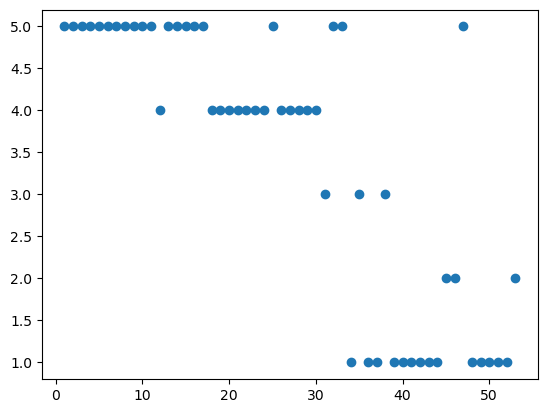

In [16]:
# compare how tfidf has ranked the candidates vs the manual score assigned
data = data.sort_values(by='similarity_rank', ascending=True)

x = data['similarity_rank']
y = data['manual_score']

plt.scatter(x, y)